# Example analysis: reading the pan-cancer results

This notebook works only from the tables in `results/`. It needs no raw data, no miner installation and no rerun of the
pipeline: pandas, numpy and matplotlib are enough, and it runs in well under a minute. Start Jupyter from the `examples/`
folder so that `../results` is found.

- **Part A** puts the ten cancers side by side: how many regulons survive each step, how well the risk models transfer to
  an independent cohort, which master regulators recur across cancers, and which transcription factors (TFs) replicate
  in more than one cancer.
- **Part B** follows one cancer (PRAD by default) from its best replicated candidate regulator down to that TF's regulons,
  their hazard ratios in both cohorts, the driver mutations upstream of them, and the transcriptional states.

Every file read here is described in `results/README.md`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = Path("../results")
assert RESULTS.is_dir(), "Start Jupyter from the examples/ folder so that ../results exists"

CANCERS = ["brca", "kirc", "luad", "lusc", "ucec", "thca", "prad", "hnsc", "lgg", "coad"]
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)


def read(cancer, name, **kwargs):
    """Reads results/<cancer>/<name> (csv, json or txt). Returns None if the file is not there."""
    path = RESULTS / cancer / name
    if not path.exists():
        return None
    if path.suffix == ".json":
        return json.loads(path.read_text())
    if path.suffix == ".txt":
        return path.read_text().strip()
    return pd.read_csv(path, **kwargs)


def read_ids(cancer, name):
    """Regulon ID lists are saved one ID per line, without a header. Returns a set of int."""
    df = read(cancer, name, header=None)
    return set() if df is None else set(df[0].astype(int))


def cohort_cox(cancer):
    """Per-regulon Cox results in the validation cohort: (cohort name, DataFrame), or (None, None) without a cohort."""
    files = sorted((RESULTS / cancer).glob("*_regulon_cox_results.csv"))
    if not files:
        return None, None
    return files[0].name.split("_regulon_cox")[0], pd.read_csv(files[0], index_col=0)


print("cancers with results:", [c for c in CANCERS if (RESULTS / c).is_dir()])

cancers with results: ['brca', 'kirc', 'luad', 'lusc', 'ucec', 'thca', 'prad', 'hnsc', 'lgg', 'coad']


## A. The ten cancers side by side

### A1. Overview

One row per cancer. `survival_in_TCGA` is the number of regulons whose eigengene is associated with survival in TCGA
(Cox p ≤ 0.05, notebook 04); `final_disease_relevant` is the number that also pass the co-expression, TF-correlation and
cohort-replication criteria; `final_pct` is the second as a share of the first, left empty for UCEC and THCA, which could not
apply the cohort-survival criterion. The two C-index columns are for the
program risk model (notebook 05): out-of-fold 5-fold cross-validation in TCGA, and the final TCGA model applied unchanged
to the independent cohort.

In [2]:
rows = []
for c in CANCERS:
    regulons = read(c, "regulonDf.csv", index_col=0)
    cox = read(c, "regulon_cox_results.csv", index_col=0)
    cv = read(c, "risk_models/tcga_cv_summary.csv", index_col=0)
    ext = read(c, "risk_models/risk_model_summary.csv", index_col=0)
    ext_col = [col for col in ext.columns if col.endswith("_OS_C")] if ext is not None else []
    rows.append({
        "cancer": c.upper(),
        "regulons": regulons["Regulon_ID"].nunique(),
        "states": len(read(c, "transcriptional_states.json")),
        "programs": len(read(c, "transcriptional_programs.json")),
        "survival_in_TCGA": int((cox["p_value"] <= 0.05).sum()),
        "final_disease_relevant": len(read_ids(c, "final_disease_relevant_regulons.csv")),
        "program_C_TCGA_cv": cv.loc["program", "OOF_C"],
        "program_C_cohort": ext.loc["program", ext_col[0]] if ext_col else np.nan,
        "validation": read(c, "validation_status.txt").split(":")[0],
    })

overview = pd.DataFrame(rows).set_index("cancer")
# The share is only comparable where the cohort-survival criterion was applied (not UCEC, not THCA)
with_cohort = overview["validation"].str.startswith("externally validated")
overview.insert(5, "final_pct", (100 * overview["final_disease_relevant"] / overview["survival_in_TCGA"]).where(with_cohort).round(0))
overview.sort_values("final_pct", ascending=False).round(3)

,regulons,states,programs,survival_in_TCGA,final_disease_relevant,final_pct,program_C_TCGA_cv,program_C_cohort,validation
cancer,,,,,,,,,
LGG,8990,23,278,6553,3115,48.0,0.753,0.721,externally validated in GRAVENDEEL_LGG
LUAD,7447,24,291,2919,1068,37.0,0.590,0.662,externally validated in GSE72094
BRCA,4596,25,157,651,208,32.0,0.594,0.537,externally validated in METABRIC
KIRC,8995,25,314,6370,1661,26.0,0.655,0.750,externally validated in EMTAB1980
COAD,7739,22,216,884,146,17.0,0.506,0.526,externally validated in GSE39582
HNSC,7609,21,284,1925,264,14.0,0.570,0.498,externally validated in GSE65858
PRAD,8422,20,238,3112,242,8.0,0.679,0.648,externally validated in GSE116918
LUSC,6644,20,257,747,26,3.0,0.499,0.513,externally validated in GSE157011
UCEC,7557,27,218,2066,1208,NaN,0.553,NaN,partly validated in CPTAC


### A2. Do the risk models transfer?

Each panel is one model type. The open circle is the TCGA cross-validated C-index, the filled circle the C-index of the
same model in the independent cohort; 0.5 (dashed) is chance. UCEC and THCA have no cohort with survival data, so only
their TCGA value is drawn.

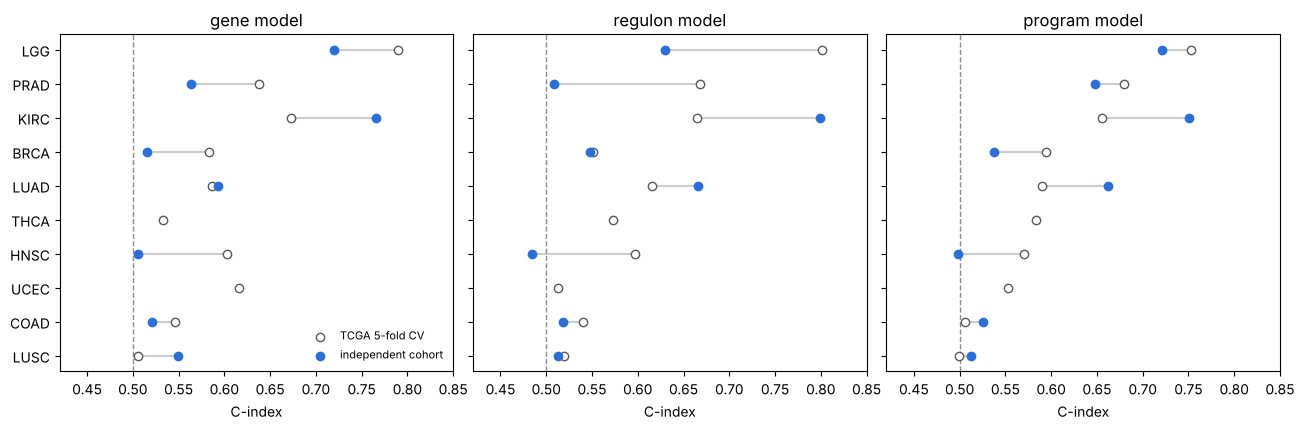

TCGA_cv                 cohort                
model     gene program regulon   gene program regulon
cancer                                               
LGG       0.79    0.75    0.80   0.72    0.72    0.63
PRAD      0.64    0.68    0.67   0.56    0.65    0.51
KIRC      0.67    0.66    0.67   0.77    0.75    0.80
BRCA      0.58    0.59    0.55   0.52    0.54    0.55
LUAD      0.59    0.59    0.62   0.59    0.66    0.67
THCA      0.53    0.58    0.57    NaN     NaN     NaN
HNSC      0.60    0.57    0.60   0.51    0.50    0.48
UCEC      0.62    0.55    0.51    NaN     NaN     NaN
COAD      0.55    0.51    0.54   0.52    0.53    0.52
LUSC      0.51    0.50    0.52   0.55    0.51    0.51

In [3]:
perf = []
for c in CANCERS:
    cv = read(c, "risk_models/tcga_cv_summary.csv", index_col=0)
    ext = read(c, "risk_models/risk_model_summary.csv", index_col=0)
    ext_col = [col for col in ext.columns if col.endswith("_OS_C")] if ext is not None else []
    for model in ["gene", "regulon", "program"]:
        perf.append({"cancer": c.upper(), "model": model, "TCGA_cv": cv.loc[model, "OOF_C"],
                     "cohort": ext.loc[model, ext_col[0]] if ext_col else np.nan})
perf = pd.DataFrame(perf)

order = perf[perf["model"] == "program"].sort_values("TCGA_cv")["cancer"].tolist()
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, model in zip(axes, ["gene", "regulon", "program"]):
    d = perf[perf["model"] == model].set_index("cancer").loc[order]
    y = np.arange(len(d))
    ax.hlines(y, d["TCGA_cv"], d["cohort"], color="0.8", zorder=1)
    ax.scatter(d["TCGA_cv"], y, facecolors="white", edgecolors="0.35", label="TCGA 5-fold CV", zorder=3)
    ax.scatter(d["cohort"], y, color="#2a6fdb", label="independent cohort", zorder=3)
    ax.axvline(0.5, ls="--", color="0.55", lw=1)
    ax.set_yticks(y, d.index)
    ax.set_xlim(0.42, 0.85)
    ax.set_xlabel("C-index")
    ax.set_title(f"{model} model")
axes[0].legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

perf.pivot(index="cancer", columns="model", values=["TCGA_cv", "cohort"]).round(2).loc[order[::-1]]

### A3. Master regulators that recur across cancers

Notebook 06 names up to three master regulators per transcriptional state. A TF that is a master regulator in many
cancers is either a general hub or a marker of a non-tumour cell type that every tumour sample contains (macrophages,
endothelium), so these are worth checking before reading them as tumour biology.

In [4]:
mr = pd.concat([read(c, "master_regulators_per_state.csv").assign(cancer=c.upper()) for c in CANCERS])
recurrent = (mr.groupby("MasterRegulator")
               .agg(n_cancers=("cancer", "nunique"), n_states=("State", "size"),
                    cancers=("cancer", lambda s: ", ".join(sorted(set(s)))))
               .sort_values(["n_cancers", "n_states"], ascending=False))
print(f"{mr['MasterRegulator'].nunique()} distinct master regulators across {len(CANCERS)} cancers; "
      f"{(recurrent['n_cancers'] >= 3).sum()} recur in 3 or more cancers")
recurrent.head(15)

139 distinct master regulators across 10 cancers; 46 recur in 3 or more cancers


,n_cancers,n_states,cancers
MasterRegulator,,,
SPI1,9,43,"BRCA, COAD, HNSC, KIRC, LGG, LUAD, LUSC, THCA, UCEC"
SOX17,8,21,"BRCA, COAD, HNSC, KIRC, LGG, LUAD, LUSC, THCA"
ELF4,8,18,"COAD, HNSC, LGG, LUAD, LUSC, PRAD, THCA, UCEC"
SP4,7,18,"COAD, HNSC, KIRC, LGG, LUAD, PRAD, UCEC"
FOXO1,7,15,"BRCA, COAD, HNSC, LGG, LUAD, LUSC, PRAD"
SOX7,6,30,"BRCA, COAD, KIRC, LUAD, THCA, UCEC"
FOXJ2,6,21,"BRCA, KIRC, LGG, LUAD, LUSC, PRAD"
FOXJ1,6,16,"COAD, HNSC, LGG, LUAD, LUSC, UCEC"
TFAP2E,6,16,"BRCA, COAD, LGG, LUAD, LUSC, UCEC"


### A4. Candidate regulators whose prognostic activity replicates in more than one cancer

In notebook 07, `act_replicated` marks TFs whose activity (the signed mean of their regulons) predicts survival in TCGA
and in the cohort, in the same direction. The sign after each cancer is the direction: `+` higher activity goes with
higher hazard, `−` with lower hazard. BRCA's notebook 07 predates this column and is skipped.

In [5]:
replicated, act_z = {}, {}
for c in CANCERS:
    t = read(c, "candidate_regulators.csv", index_col=0)
    if "act_replicated" not in t.columns:
        print(f"{c.upper()}: no act_replicated column (notebook 07 predates it), skipped")
        continue
    replicated[c.upper()] = set(t.index[t["act_replicated"] == True])
    act_z[c.upper()] = t["act_z"]

print(pd.Series({c: len(s) for c, s in replicated.items()}, name="replicated TFs").to_string())

counts = pd.Series([tf for s in replicated.values() for tf in s]).value_counts()
multi = counts[counts >= 2]
pd.DataFrame({
    "n_cancers": multi,
    "cancers (direction)": [", ".join(f"{c}{'+' if act_z[c][tf] > 0 else '−'}" for c, s in replicated.items() if tf in s)
                            for tf in multi.index],
}).head(20)

BRCA: no act_replicated column (notebook 07 predates it), skipped
KIRC    130
LUAD     92
LUSC      2
UCEC      0
THCA      0
PRAD     13
HNSC     18
LGG     232
COAD      5


,n_cancers,cancers (direction)
IRX6,4,"KIRC+, LUAD−, LUSC−, HNSC−"
FOXD1,4,"KIRC+, PRAD+, HNSC+, LGG+"
CEBPA,3,"KIRC+, HNSC−, LGG+"
PPARG,3,"KIRC−, LGG+, COAD−"
TGIF1,3,"KIRC−, LUAD+, LGG+"
MAFK,3,"KIRC−, LUAD+, LGG+"
TFAP2A,3,"KIRC+, LUAD+, LGG−"
CEBPB,3,"KIRC+, LUAD+, LGG+"
HOXD9,3,"KIRC−, LUAD+, LGG+"
HOXD3,3,"KIRC−, LUAD−, LGG+"


## B. One cancer in detail

Change `CANCER` to any of the ten. The cells below take the shortlisted candidate regulators (replicated activity, or the
RRA ranking where notebook 07 predates that column) and follow one of them down the pipeline.

`regulonDf.csv` names regulators by Ensembl ID, while notebooks 06 and 07 use gene symbols. With miner installed, its
identifier table links the two for any TF. Without it, the link comes from the driver-filtered causal flows, which name the
TF by symbol and its regulons by ID, so only TFs downstream of a driver mutation can be traced; the cells then pick the
best-ranked such TF.

In [6]:
def ensembl_of(symbol, regulons, flows):
    """Ensembl ID(s) under which regulonDf.csv lists a TF: miner's identifier table if miner is installed, else the causal flows."""
    try:
        import miner.miner as miner
        ids = pd.read_csv(Path(miner.__file__).parent / "data" / "identifier_mappings.txt", sep="\t")
        hits = ids.loc[(ids["Source"] == "Gene Name") & (ids["Name"] == symbol), "Preferred_Name"].unique().tolist()
        hits = [h for h in hits if h in set(regulons["Regulator"])]
        if hits:
            return hits, "miner identifier table"
    except Exception:
        pass
    traced = flows.loc[flows["Regulator"] == symbol, "Regulon"]
    return regulons.loc[regulons["Regulon_ID"].isin(traced), "Regulator"].mode().tolist(), "driver causal flows"

In [7]:
CANCER = "prad"

cand = read(CANCER, "candidate_regulators.csv", index_col=0)
ext_z = [col for col in cand.columns if col.startswith("act_z_") and col != "act_z_TCGA"]
replicated_here = cand[cand["act_replicated"] == True] if "act_replicated" in cand.columns else cand.iloc[:0]
if len(replicated_here):
    shortlist, basis = replicated_here.sort_values("act_p"), "activity replicated in both cohorts"
else:                                   # no column (BRCA) or no replicated TF (UCEC, THCA): top 10 of the RRA ranking
    shortlist, basis = cand.sort_values("rra_p").head(10), "top 10 by RRA (no replicated TFs available)"
cols = ["n_regulons", "n_final", "act_z_TCGA"] + ext_z + ["act_fdr", "rra_fdr", "upstream_drivers", "n_states_master"]
print(f"{CANCER.upper()}: {len(cand)} TFs ranked, {len(shortlist)} shortlisted ({basis}); "
      f"validation: {read(CANCER, 'validation_status.txt')}")
shortlist[cols].round(3)

PRAD: 626 TFs ranked, 13 shortlisted (activity replicated in both cohorts); validation: externally validated in GSE116918: co-expression and survival (paper's rule, criteria 1-5)


,n_regulons,n_final,act_z_TCGA,act_z_GSE116918,act_fdr,rra_fdr,upstream_drivers,n_states_master
TF,,,,,,,,
EGR3,2,1,-4.261,-3.012,0.000,0.825,NaN,0
E2F1,14,0,4.318,2.105,0.000,0.875,NaN,0
KLF4,16,0,-3.794,-2.285,0.001,0.967,NaN,0
HINFP,6,0,3.973,2.015,0.001,0.991,NaN,0
HSF1,24,1,3.607,2.368,0.001,0.997,TP53,0
HOXA5,11,0,-2.026,-4.425,0.001,0.997,NaN,0
RXRB,9,1,3.615,2.150,0.002,0.997,NaN,0
NR4A1,6,1,-3.263,-2.115,0.004,0.825,TP53,0
TBX1,12,2,2.954,2.204,0.008,0.364,"FOXA1, SPOP",0


### B1. One TF's regulons

The first shortlisted TF that can be traced to its regulons (see above). Set `TF` by hand to follow another one. Hazard
ratios are per unit of the regulon's eigengene (Cox models of notebook 04).

In [8]:
flows = read(CANCER, "driverCausalResults.csv")
reg = read(CANCER, "regulonDf.csv", index_col=0)
cox = read(CANCER, "regulon_cox_results.csv", index_col=0)
cohort_name, cox_ext = cohort_cox(CANCER)
final = read_ids(CANCER, "final_disease_relevant_regulons.csv")

TF, ensembl, how = None, [], ""
for candidate in shortlist.index:
    ensembl, how = ensembl_of(candidate, reg, flows)
    if ensembl:
        TF = candidate
        break
assert TF is not None, "no shortlisted TF could be traced; install miner or pick TF by hand"
skipped = list(shortlist.index[:list(shortlist.index).index(TF)])
if skipped:
    print(f"not traceable without miner (no driver flows): {', '.join(skipped)}")

tf_flows = flows[flows["Regulator"] == TF]
tf_regs = sorted(reg.loc[reg["Regulator"].isin(ensembl), "Regulon_ID"].unique())
genes = reg.groupby("Regulon_ID")["Gene"].nunique()

table = pd.DataFrame({
    "genes": genes.reindex(tf_regs),
    "HR_TCGA": cox["HR"].reindex(tf_regs),
    "p_TCGA": cox["p_value"].reindex(tf_regs),
}, index=pd.Index(tf_regs, name="regulon"))
if cox_ext is not None:
    table[f"HR_{cohort_name}"] = cox_ext["HR"].reindex(tf_regs)
    table[f"p_{cohort_name}"] = cox_ext["p_value"].reindex(tf_regs)
table["final_disease_relevant"] = [r in final for r in tf_regs]
table["upstream_mutations"] = (tf_flows.groupby("Regulon")["Mutation"]
                               .agg(lambda s: ", ".join(sorted(set(s)))).reindex(tf_regs).fillna(""))

print(f"{TF} = {', '.join(ensembl)} (via {how}): {len(tf_regs)} regulons "
      f"(notebook 07 counted {cand.loc[TF, 'n_regulons']}), {int(table['final_disease_relevant'].sum())} disease-relevant, "
      f"{len(tf_flows)} driver causal flows from {tf_flows['Mutation'].nunique()} mutated genes")
table.round(3)

not traceable without miner (no driver flows): EGR3
E2F1 = ENSG00000101412 (via driver causal flows): 14 regulons (notebook 07 counted 14), 0 disease-relevant, 11 driver causal flows from 2 mutated genes


,genes,HR_TCGA,p_TCGA,HR_gse116918,p_gse116918,final_disease_relevant,upstream_mutations
regulon,,,,,,,
2908,209,0.895,0.320,0.922,0.534,False,SPOP
2909,24,1.640,0.000,1.255,0.063,False,"SPOP, TP53"
2910,18,0.621,0.000,0.763,0.026,False,SPOP
2911,16,1.121,0.319,1.132,0.372,False,
2912,15,1.673,0.000,0.947,0.678,False,TP53
2913,12,1.296,0.023,0.930,0.582,False,TP53
2914,9,1.591,0.000,1.125,0.403,False,TP53
2915,9,1.933,0.000,1.030,0.825,False,TP53
2916,8,0.856,0.183,0.931,0.592,False,SPOP


### B2. Do regulon hazard ratios agree between the two cohorts?

Every regulon's log2 hazard ratio in TCGA against the cohort. Grey: all regulons; dark grey: the final disease-relevant
ones; blue: the regulons of the TF chosen above.

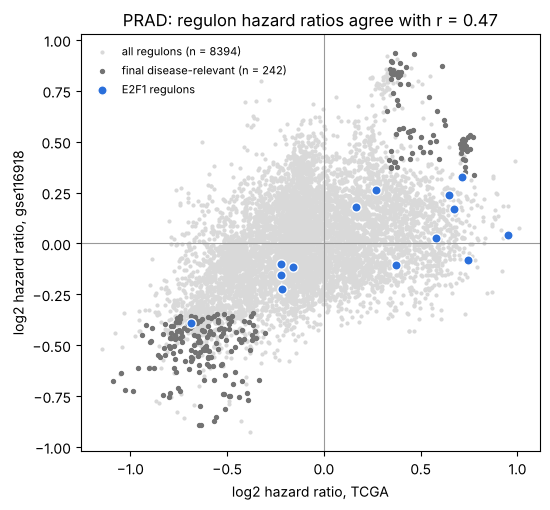

In [9]:
if cox_ext is None:
    print(f"{CANCER.upper()} has no validation cohort with survival data")
else:
    both = pd.DataFrame({"TCGA": np.log2(cox["HR"]), "cohort": np.log2(cox_ext["HR"])}).dropna()
    fin = both[both.index.isin(final)]
    mine = both[both.index.isin(tf_regs)]
    r_all = np.corrcoef(both["TCGA"], both["cohort"])[0, 1]

    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    ax.scatter(both["TCGA"], both["cohort"], s=4, color="0.85", label=f"all regulons (n = {len(both)})")
    ax.scatter(fin["TCGA"], fin["cohort"], s=8, color="0.45", label=f"final disease-relevant (n = {len(fin)})")
    ax.scatter(mine["TCGA"], mine["cohort"], s=45, color="#2a6fdb", edgecolor="white", label=f"{TF} regulons")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.axvline(0, color="0.6", lw=0.8)
    ax.set_xlabel("log2 hazard ratio, TCGA")
    ax.set_ylabel(f"log2 hazard ratio, {cohort_name}")
    ax.set_title(f"{CANCER.upper()}: regulon hazard ratios agree with r = {r_all:.2f}")
    ax.legend(fontsize=8, frameon=False, loc="upper left")
    fig.tight_layout()
    plt.show()

### B3. Transcriptional states and their master regulators

States are groups of patients with similar regulon activity (notebook 02); notebook 06 ranks master regulators within
each state. The table lists the largest states first.

In [10]:
states = read(CANCER, "transcriptional_states.json")
mr_c = read(CANCER, "master_regulators_per_state.csv")
summary = read(CANCER, "master_regulator_state_summary.csv", index_col=0)

hits = mr_c[mr_c["MasterRegulator"] == TF]
print(f"{TF} is a master regulator of {hits['State'].nunique()} {CANCER.upper()} state(s)"
      + (f": {sorted(hits['State'].tolist())}" if len(hits) else ""))

per_state = (mr_c.sort_values("Rank").groupby("State")["MasterRegulator"].agg(", ".join)
             .rename("master_regulators"))
view = pd.DataFrame({"patients": pd.Series({int(k): len(v) for k, v in states.items()})})
view = view.join(summary[["n_state_regulons", "edges_after_pruning"]]).join(per_state)
view.sort_values("patients", ascending=False).head(12)

E2F1 is a master regulator of 0 PRAD state(s)


,patients,n_state_regulons,edges_after_pruning,master_regulators
0,95,2032,35,"ZNF35, IRF3, FOXJ2"
1,60,2738,97,"SP4, HOXA13, NKX3-1"
9,60,3157,158,"CEBPA, ZNF35, FOXJ3"
3,43,2270,61,"FLI1, PGR, FOXO1"
4,43,2394,5,"FOXJ2, RFX2, GATA3"
17,26,2248,63,"MEF2A, TCF3, ELF4"
13,25,2095,58,"CEBPA, TP63, ELF4"
5,24,2579,102,"PGR, ELF4, TCF7L1"
6,20,1399,54,"SOX15, ELF4, TP63"
15,14,1645,15,"SOX15, FOXA1, SOX2"


## Going further

- **Gene symbols.** Regulon genes in `regulonDf.csv` are Ensembl IDs. With miner installed, its own table maps them:
  `pd.read_csv(Path(miner.__file__).parent / "data" / "identifier_mappings.txt", sep="\t")`, keeping rows whose `Source`
  is `Gene Name`.
- **Another cancer.** Set `CANCER` in Part B and rerun from there.
- **What is not here.** Eigengenes, per-patient regulon activity and the full causal tables are too large for the
  repository; they are written by notebooks 02–05 when the pipeline is rerun (see the main README).